# K-Nearest Neighbors and Decision Trees for Regression — INSTRUCTOR SOLUTION

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

**How to use this notebook.** The sketch-and-discuss questions get a written answer *and* the code that draws
the sketch, so the expected picture is on screen. The coding questions (11–14) are answered in five beats:
**Approach** → **code** (complete and executed) → **What the code does** → **Expected output** → **Common
mistakes**. Everything else is the student notebook, unchanged.

**Links to the topic.** Topic 9.1 and its animation page (`week_9/algorithms.html` on the course site) show
the same three mechanisms on eight houses: the line, the k nearest neighbors and their average, the SSE-scored
splits of a tree. The wine questions here are the same ideas on 27 vintages.

Model names used below: `knn1`, `knn2`, `knn27`, `knn_model` (the notebook's own name for the neighborhood
model), `knn_pipe`, `tree_pipe`. Random splits use `random_state=5544`.

*Note on the K = 1 cell further down:* the comment `# ADD YOUR CODE HERE,` inside `pd.Series(...)` is a
leftover in the student notebook; the prediction line below it is already complete and the cell runs as is.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

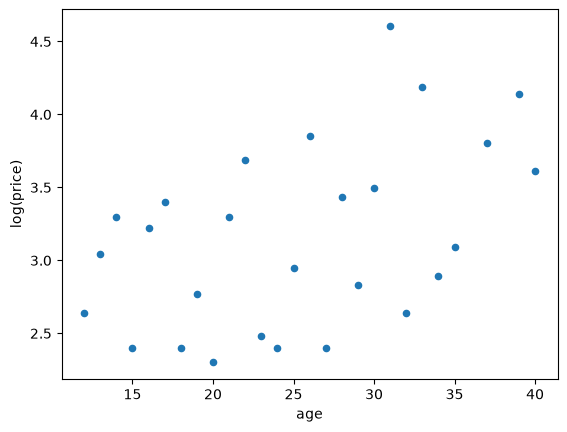

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

**Answer 1 (1-nearest neighbor).** The regression function is a **staircase**. For any age, the prediction is
the log price of the single closest training vintage, so between two training ages nothing changes and the
function is flat; it jumps at the **midpoints** between consecutive training ages (12.5, 13.5, 14.5, …). The
function passes through every training point.

| age | nearest training age | prediction |
|---|---|---|
| 12 | 12 (the 1980 vintage) | 2.64 |
| 13 | 13 (1979) | 3.04 |
| 11.5 | 12 (nothing is closer on the left) | 2.64 |
| 12.49 | 12 | 2.64 |
| 12.51 | 13 | 3.04 |
| 13.49 | 13 | 3.04 |
| 13.51 | 14 (1978) | 3.30 |

The code below checks the table and draws the staircase.

In [5]:
from sklearn.neighbors import KNeighborsRegressor

knn1 = KNeighborsRegressor(n_neighbors=1).fit(X_train, y_train)
ages = pd.DataFrame({"age": [12, 13, 11.5, 12.49, 12.51, 13.49, 13.51]})
ages["predicted"] = knn1.predict(ages).round(3)
ages

,age,predicted
0,12.00,2.639
1,13.00,3.045
2,11.50,2.639
3,12.49,2.639
4,12.51,3.045
5,13.49,3.045
6,13.51,3.296


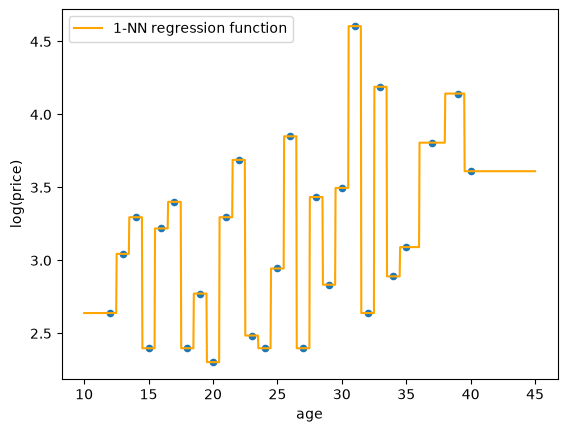

In [6]:
grid = pd.DataFrame({"age": np.linspace(10, 45, 1000)})
ax = bordeaux_train.plot.scatter(x="age", y="log(price)")
ax.plot(grid["age"], knn1.predict(grid), color="orange", label="1-NN regression function")
ax.legend();

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

**Answer 2 (2-nearest neighbors).** Still a staircase, but each step is the **average of two** vintages, so
the function no longer passes through the points, and the jumps move: the pair of nearest ages changes at the
**training ages themselves**, not at the midpoints. Between 12 and 13 the two nearest are {12, 13}; between 13
and 14 they are {13, 14}.

| age | two nearest ages | prediction |
|---|---|---|
| 12 | 12 and 13 | (2.639 + 3.045) / 2 = 2.84 |
| 12.99 | 12 and 13 | 2.84 |
| 13.01 | 13 and 14 | (3.045 + 3.296) / 2 = 3.17 |
| 13.99 | 13 and 14 | 3.17 |
| 14.01 | 14 and 15 | (3.296 + 2.398) / 2 = 2.85 |

At *exactly* age 13 the second neighbor is a tie (12 and 14 are both one year away); scikit-learn breaks the
tie arbitrarily (here it picks 14, giving 3.17). Ties only matter at the jump points.

In [7]:
knn2 = KNeighborsRegressor(n_neighbors=2).fit(X_train, y_train)
ages = pd.DataFrame({"age": [12, 12.99, 13, 13.01, 13.99, 14, 14.01]})
ages["predicted"] = knn2.predict(ages).round(3)
ages

,age,predicted
0,12.00,2.842
1,12.99,2.842
2,13.00,3.170
3,13.01,3.170
4,13.99,3.170
5,14.00,2.847
6,14.01,2.847


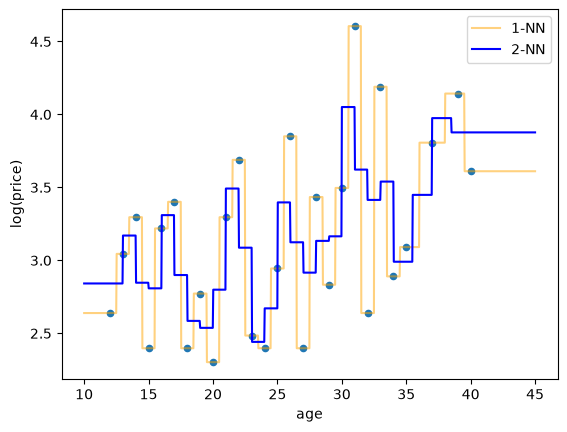

In [8]:
ax = bordeaux_train.plot.scatter(x="age", y="log(price)")
ax.plot(grid["age"], knn1.predict(grid), color="orange", alpha=0.5, label="1-NN")
ax.plot(grid["age"], knn2.predict(grid), color="blue", label="2-NN")
ax.legend();

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

**Answer 3 (27-nearest neighbors).** 27 is the **number of training vintages** (1952–1980, minus the two
missing years). Whatever the age, the 27 nearest neighbors are *all* the training wines, so every prediction is
the same number: the mean log price, **3.158**. The regression function is a **horizontal line** at the mean,
and it ignores age completely.

In [9]:
knn27 = KNeighborsRegressor(n_neighbors=27).fit(X_train, y_train)
print("number of training wines:", len(X_train))
print("mean log(price):", round(y_train.mean(), 3))
print("27-NN predictions at ages 12, 25, 40:", knn27.predict(pd.DataFrame({"age": [12, 25, 40]})).round(3))

number of training wines: 27
mean log(price): 3.158
27-NN predictions at ages 12, 25, 40: [3.158 3.158 3.158]


4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

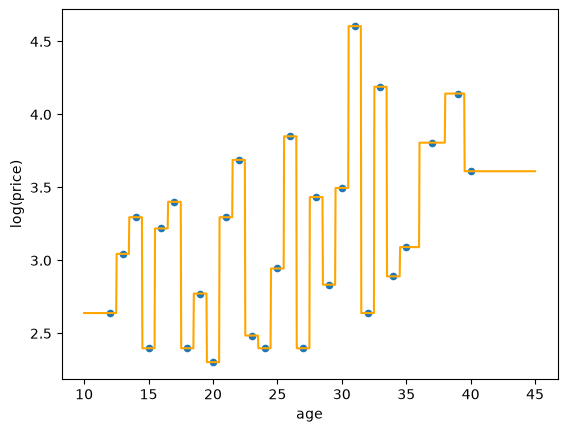

In [10]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


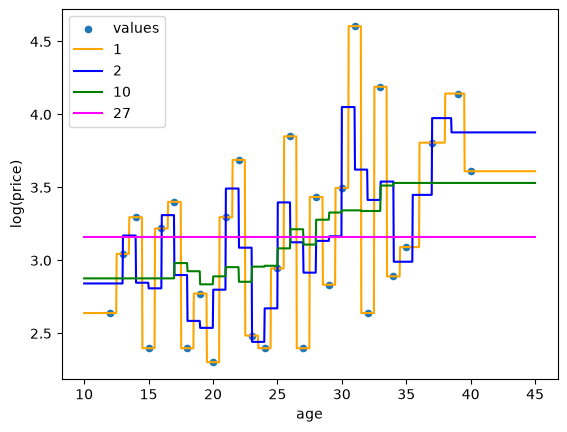

In [11]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


**Discussion 4 (K = 1, 2, 10, 27).** The functions should look like the sketches: K = 1 is the jagged orange
staircase through every point; K = 2 (blue) averages pairs and is slightly smoother; K = 10 (green) is a slow
wave that follows the general rise of price with age; K = 27 (magenta) is flat at the mean. **As K increases
the function gets smoother and less flexible.** Small K fits the training data closely, noise included (K = 1
has zero training error); large K averages over so many wines that it stops responding to age at all. Neither
extreme predicts *new* vintages well; a middle K is chosen on test data, which is what questions 12 and 14
practise.

### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [12]:
df_ames = pd.read_csv("http://dlsun.github.io/pods/data/AmesHousing.txt", sep = "\t")

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,ex

Now we'll find the predicted price for each Neighborhood.

In [14]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [15]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

**Answer 5 (neighborhoods).** The only neighborhood whose predicted price **equals its mean** is **Blueste**,
which has **exactly 10 houses**.

Why: after one-hot encoding, every house in the same neighborhood has *identical* features, so all of them are
at distance 0 from the query, and every house in any other neighborhood is at distance √2. The 10-nearest
neighbors of "Blueste" are therefore precisely its 10 houses, and the prediction is their mean.

- A neighborhood with **more than 10 houses** (NAmes has 443): 443 houses tie at distance 0, and scikit-learn
  keeps *some* 10 of them; which 10 is an arbitrary tie-break, not the first ten rows. The prediction is the mean
  of those 10 houses, not of all 443 (142,771 versus 145,097 for NAmes).
- A neighborhood with **fewer than 10 houses** (Greens 8, GrnHill 2, Landmrk 1): its own houses are used, then
  the remaining neighbors are filled from *other* neighborhoods, all tied at distance √2, so the prediction is
  pulled toward those neighborhoods' prices (GrnHill: 150,790 predicted versus a mean of 280,000).

A categorical feature with KNN therefore behaves like a group mean only when the group size happens to equal
k. The code shows the neighbor counts and which houses the model actually used.

In [16]:
counts = df_ames["Neighborhood"].value_counts()
print("neighborhoods with 10 or fewer houses:")
print(counts[counts <= 10])

def neighbors_used(neighborhood):
    query = knn_model["preprocessing"].transform(pd.DataFrame({"Neighborhood": [neighborhood]}))
    dist, idx = knn_model["knn"].kneighbors(query)
    used = df_ames.iloc[idx[0]][["Neighborhood", "SalePrice"]].assign(distance=dist[0].round(2))
    print(f"\n{neighborhood}: {counts[neighborhood]} houses in the data; predicted = mean of these 10 = {used['SalePrice'].mean():,.0f}")
    return used

neighbors_used("Blueste")

neighborhoods with 10 or fewer houses:
Neighborhood
Blueste    10
Greens      8
GrnHill     2
Landmrk     1
Name: count, dtype: int64

Blueste: 10 houses in the data; predicted = mean of these 10 = 143,590


,Neighborhood,SalePrice,distance
298,Blueste,185000,0.0
932,Blueste,115000,0.0
1542,Blueste,116500,0.0
1543,Blueste,151000,0.0
2227,Blueste,200000,0.0
935,Blueste,124000,0.0
934,Blueste,121000,0.0
933,Blueste,137000,0.0
2225,Blueste,123900,0.0
299,Blueste,162500,0.0


In [17]:
neighbors_used("GrnHill")


GrnHill: 2 houses in the data; predicted = mean of these 10 = 150,790


,Neighborhood,SalePrice,distance
2256,GrnHill,330000,0.00
2892,GrnHill,230000,0.00
1953,NAmes,120000,1.41
1955,NAmes,135000,1.41
1954,NAmes,128500,1.41
1956,NAmes,122900,1.41
1949,OldTown,64500,1.41
1950,OldTown,148000,1.41
1958,NAmes,143000,1.41
1951,OldTown,86000,1.41


### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Answer 6 (1-NN, two training points).** The feature plane is cut in two by the **perpendicular bisector** of
the segment joining the two points. Every location on A's side is closer to A, so the surface is flat at A's
target there; on B's side it is flat at B's target. Two flat plateaus with a straight cliff between them.

In [18]:
def knn_surface(points, targets, k, title):
    """Draw the KNN regression surface for a tiny two-feature training set (features already scaled)."""
    pts = pd.DataFrame(points, columns=["x1", "x2"])
    model = KNeighborsRegressor(n_neighbors=k).fit(pts, targets)
    g1, g2 = np.meshgrid(np.linspace(0, 5, 251), np.linspace(0, 5, 251))
    z = model.predict(pd.DataFrame({"x1": g1.ravel(), "x2": g2.ravel()})).reshape(g1.shape)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cs = ax.contourf(g1, g2, z, levels=sorted(set(np.round(z.ravel(), 6))) + [z.max() + 1], cmap="viridis")
    fig.colorbar(cs, ax=ax, label="predicted y")
    ax.scatter(pts["x1"], pts["x2"], c="white", edgecolor="black", s=90, zorder=3)
    for (a, b), t in zip(points, targets):
        ax.annotate(f"y = {t}", (a, b), xytext=(7, 7), textcoords="offset points", color="white", fontweight="bold")
    ax.set_xlabel("feature 1 (scaled)"); ax.set_ylabel("feature 2 (scaled)"); ax.set_title(title)

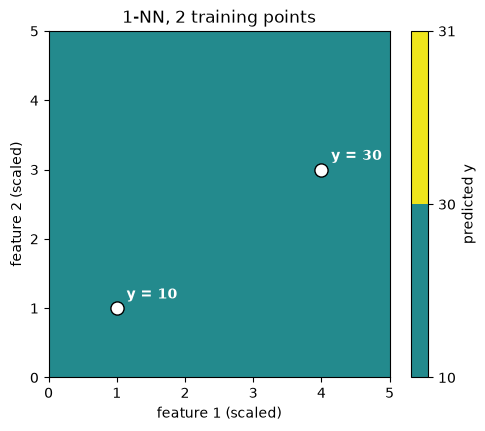

In [19]:
knn_surface(points=[(1, 1), (4, 3)], targets=[10, 30], k=1, title="1-NN, 2 training points")

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Answer 7 (1-NN, three training points).** Three flat regions, one per training point: each region is the
set of locations closer to that point than to the other two (its *Voronoi cell*). The boundaries are the three
perpendicular bisectors, which meet at a single point equidistant from all three observations.

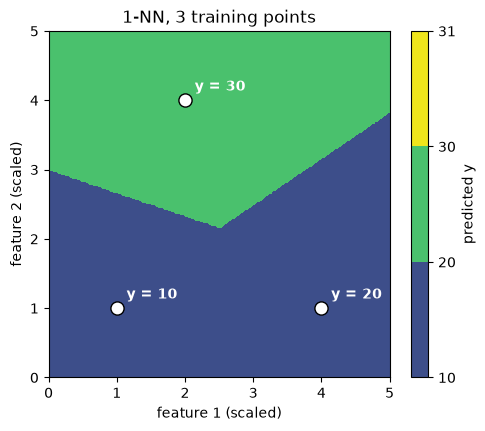

In [20]:
knn_surface(points=[(1, 1), (4, 1), (2, 4)], targets=[10, 20, 30], k=1, title="1-NN, 3 training points")

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Answer 8 (2-NN, three training points).** Again three flat regions with the *same* bisector boundaries, but
the values and the geometry flip: with k = 2 each prediction is the mean of the **two closest** points, which is
"everything except the farthest". So the region where C is farthest predicts (y_A + y_B)/2 = 15, the region where
B is farthest predicts (y_A + y_C)/2 = 20, and the region where A is farthest predicts (y_B + y_C)/2 = 25. Each
region now sits *opposite* its excluded point rather than around its own point.

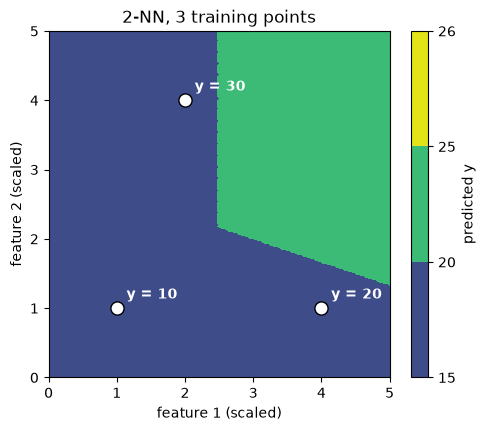

In [21]:
knn_surface(points=[(1, 1), (4, 1), (2, 4)], targets=[10, 20, 30], k=2, title="2-NN, 3 training points")

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

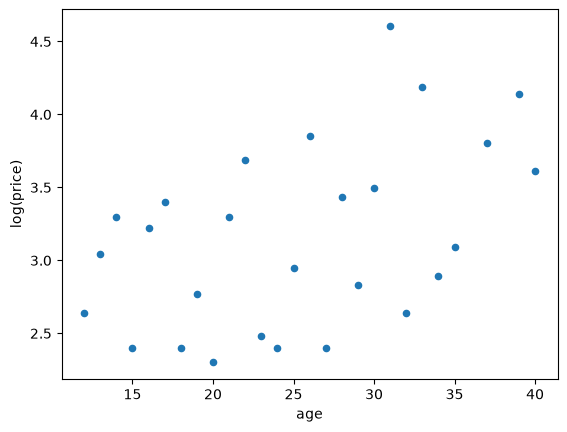

In [22]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

**Answer 9 (one split at 20.5).** A tree with one split is a **two-step staircase**: for age ≤ 20.5 it predicts
the mean log price of those vintages (9 wines, **2.830**); for age > 20.5 the mean of the rest (18 wines,
**3.322**). One vertical jump at 20.5, flat on either side.

               mean  count
age                       
(-inf, 20.5]  2.830      9
(20.5, inf]   3.322     18


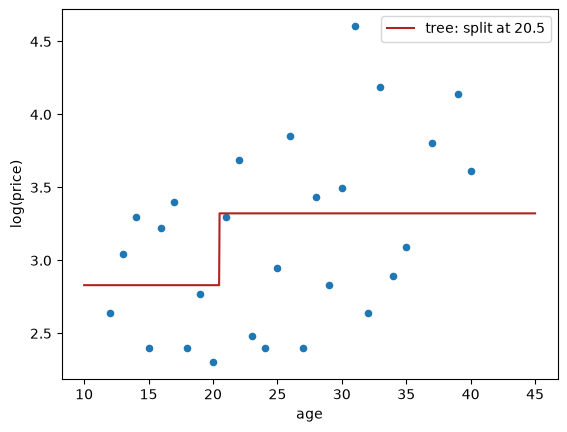

In [23]:
def tree_steps(splits):
    """Group means for a tree whose thresholds on age are `splits`, as a step function on the grid."""
    bins = [-np.inf] + list(splits) + [np.inf]
    means = bordeaux_train.groupby(pd.cut(bordeaux_train["age"], bins), observed=True)["log(price)"].agg(["mean", "count"])
    grid_bins = pd.cut(grid["age"], bins)
    return means, grid_bins.map(means["mean"]).astype(float)

means1, step1 = tree_steps([20.5])
print(means1.round(3))
ax = bordeaux_train.plot.scatter(x="age", y="log(price)")
ax.plot(grid["age"], step1, color="firebrick", label="tree: split at 20.5")
ax.legend();

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

**Answer 10 (splits at 20.5 and 30.5).** Three steps: **2.830** for age ≤ 20.5 (9 wines), **3.082** for 20.5 <
age ≤ 30.5 (10 wines), **3.622** for age > 30.5 (8 wines). Each extra split adds one more flat segment; the
second split is applied inside the right-hand group of question 9, which is how a tree grows — it never redraws
earlier splits.

               mean  count
age                       
(-inf, 20.5]  2.830      9
(20.5, 30.5]  3.082     10
(30.5, inf]   3.622      8


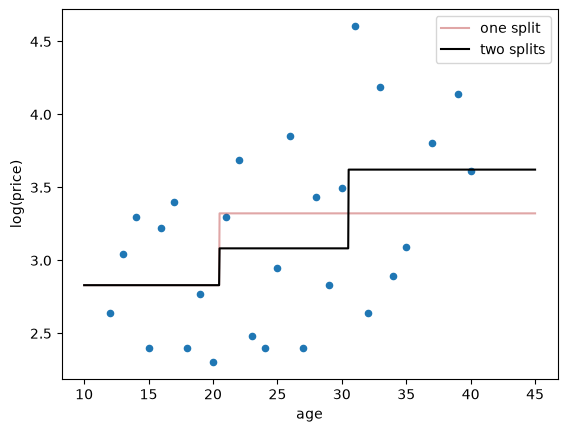

In [24]:
means2, step2 = tree_steps([20.5, 30.5])
print(means2.round(3))
ax = bordeaux_train.plot.scatter(x="age", y="log(price)")
ax.plot(grid["age"], step1, color="firebrick", alpha=0.4, label="one split")
ax.plot(grid["age"], step2, color="black", label="two splits")
ax.legend();

## Fitting KNN Regression Models with scikit-learn: Housing data

11. Fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a pipeline and column transformers as needed. Make a scatter plot of predicting price versus actual price.

### Solution 11 — 10-NN with five features, in a pipeline

**Approach.** Two kinds of columns, two preprocessing steps in one `ColumnTransformer`: `OneHotEncoder` for
`Neighborhood` and `StandardScaler` for the four numeric features (KNN measures distances, and square feet
would otherwise swamp bedrooms and bathrooms). Chain it with `KNeighborsRegressor(n_neighbors=10)` in a
`Pipeline`, fit on all 2,930 houses as the question asks, predict, and plot predicted against actual with a
45° reference line.

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath", "Neighborhood"]
numeric  = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
X = df_ames[features]
y = df_ames["SalePrice"]

preprocessing = ColumnTransformer([
    ("dummify", OneHotEncoder(handle_unknown="ignore"), ["Neighborhood"]),
    ("scale",   StandardScaler(), numeric),
])
knn_pipe = Pipeline([
    ("preprocessing", preprocessing),
    ("knn", KNeighborsRegressor(n_neighbors=10)),
])
knn_pipe.fit(X, y)

df_ames["predicted_knn10"] = knn_pipe.predict(X)
print("RMSE on the fitted data:", round(root_mean_squared_error(y, df_ames["predicted_knn10"])))

RMSE on the fitted data: 34695


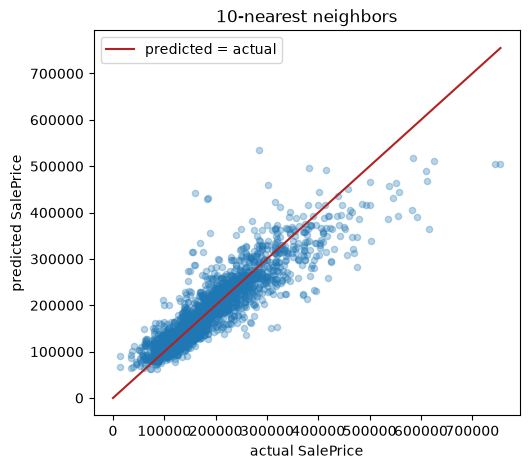

In [26]:
def predicted_vs_actual(predicted, title):
    ax = df_ames.plot.scatter(x="SalePrice", y=predicted, alpha=0.3, figsize=(5.5, 5))
    lim = [0, df_ames["SalePrice"].max()]
    ax.plot(lim, lim, color="firebrick", label="predicted = actual")
    ax.set_xlabel("actual SalePrice"); ax.set_ylabel("predicted SalePrice"); ax.set_title(title); ax.legend()

predicted_vs_actual("predicted_knn10", "10-nearest neighbors")

**What the code does.** `ColumnTransformer` routes each column to its own transformer and concatenates the
results (28 dummy columns + 4 scaled columns); `Pipeline` makes the whole thing one model with `fit` and
`predict`. `handle_unknown="ignore"` lets `predict` cope with a neighborhood it has not seen (it matters once we
split the data in question 12). The helper plots predictions against the truth.

**Expected output.** RMSE about **34,700** dollars on the houses the model was fitted on. The cloud follows the
45° line with a fan that widens for expensive houses, and a few very large homes on the right are badly
under-predicted (their ten nearest neighbors are cheaper).

**Common mistakes.**
- Leaving the numeric features **unscaled**: `Gr Liv Area` (hundreds to thousands of square feet) then
  dominates every distance and the bedroom/bath columns are ignored; test RMSE in question 12 is about 56,500
  instead of 40,100 with `random_state=5544`.
- Putting `Neighborhood` through the scaler (it is text) or forgetting it in the `ColumnTransformer` (columns
  not named are **dropped** by default; `remainder="passthrough"` keeps them).
- Plotting the log of price: the question asks for `SalePrice` itself.

12. Repeat the previous part to fit a $k$-nearest neighbors model for some other value of $k$. Experiment with different values of $k$. (For this, you can just pick and choose a few, no need to automate it. We'll see how to do that later.) What value of $k$ seems to be "best"? How are you deciding?

### Solution 12 — choosing k

**Approach.** "Best" has to mean *best at predicting houses the model has not seen*, so hold out a test set
(`train_test_split`, 25 %, `random_state=5544`) and compare **test RMSE** across a handful of k. Training RMSE is
shown alongside to make the point that it cannot be used: k = 1 reproduces the training prices almost exactly.

In [27]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=5544)

rows = []
for k in [1, 3, 5, 10, 20, 50, 100]:
    pipe = Pipeline([("preprocessing", preprocessing), ("knn", KNeighborsRegressor(n_neighbors=k))])
    pipe.fit(X_tr, y_tr)
    rows.append({"k": k,
                 "train RMSE": root_mean_squared_error(y_tr, pipe.predict(X_tr)),
                 "test RMSE":  root_mean_squared_error(y_te, pipe.predict(X_te))})
k_results = pd.DataFrame(rows).set_index("k").round(0)
k_results

,train RMSE,test RMSE
k,,
1,6749.0,46898.0
3,28052.0,37954.0
5,31921.0,38321.0
10,34888.0,40113.0
20,38729.0,41820.0
50,43360.0,45028.0
100,47104.0,46654.0


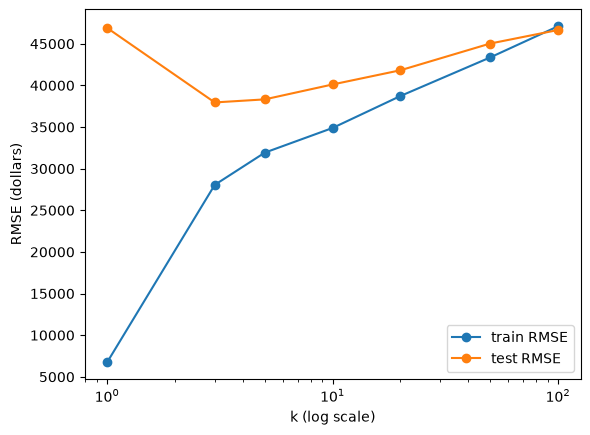

In [28]:
ax = k_results.plot(marker="o", logx=True)
ax.set_ylabel("RMSE (dollars)"); ax.set_xlabel("k (log scale)");

**What the code does.** One split, then the same pipeline refitted for each k on the training rows only.
Both errors are computed from the same fitted model: on the rows it saw (train) and on the rows it did not
(test).

**Expected output (random_state 5544).**

| k | train RMSE | test RMSE |
|---|---|---|
| 1 | ≈ 6,700 | ≈ 46,900 |
| 3 | ≈ 28,100 | **≈ 38,000** |
| 5 | ≈ 31,900 | ≈ 38,300 |
| 10 | ≈ 34,900 | ≈ 40,100 |
| 20 | ≈ 38,700 | ≈ 41,800 |
| 50 | ≈ 43,400 | ≈ 45,000 |
| 100 | ≈ 47,100 | ≈ 46,700 |

Training RMSE rises steadily with k (k = 1 is nearly perfect on the training rows, exactly the wine staircase
through every point). Test RMSE is U-shaped: worst at k = 1, best around **k = 3 to 5**, then slowly worse as the
average pulls in houses that are not really similar. **How to decide:** by test error, and since the two best
values are close, prefer the one that is less jumpy (k = 5) or, better, cross-validate — one split is one random
draw, and a different `random_state` can swap 3 and 5.

**Common mistakes.**
- Judging by training RMSE and concluding k = 1 is best.
- Fitting on all the data and then "testing" on part of it (the test rows were seen in training).
- Splitting *after* fitting the preprocessing on everything: the pipeline avoids this because `fit` on `X_tr`
  learns the scaler on training rows only.

13. Fit a regression decison tree that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Use a max depth of 4. Use a pipeline and column transformers as needed. Plot and interpret the tree. Also, make a scatter plot of predicting price versus actual price.

### Solution 13 — a regression tree of depth 4

**Approach.** Same five features and the same pipeline shape, with two changes. A tree does not need scaling
(each question is about one feature), so the numeric columns pass through untouched and the thresholds in the
plot stay in square feet and bedrooms; `remainder="passthrough"` does that. Then `DecisionTreeRegressor(
max_depth=4)`, `plot_tree` with the feature names the transformer produced, and the same predicted-versus-actual
plot.

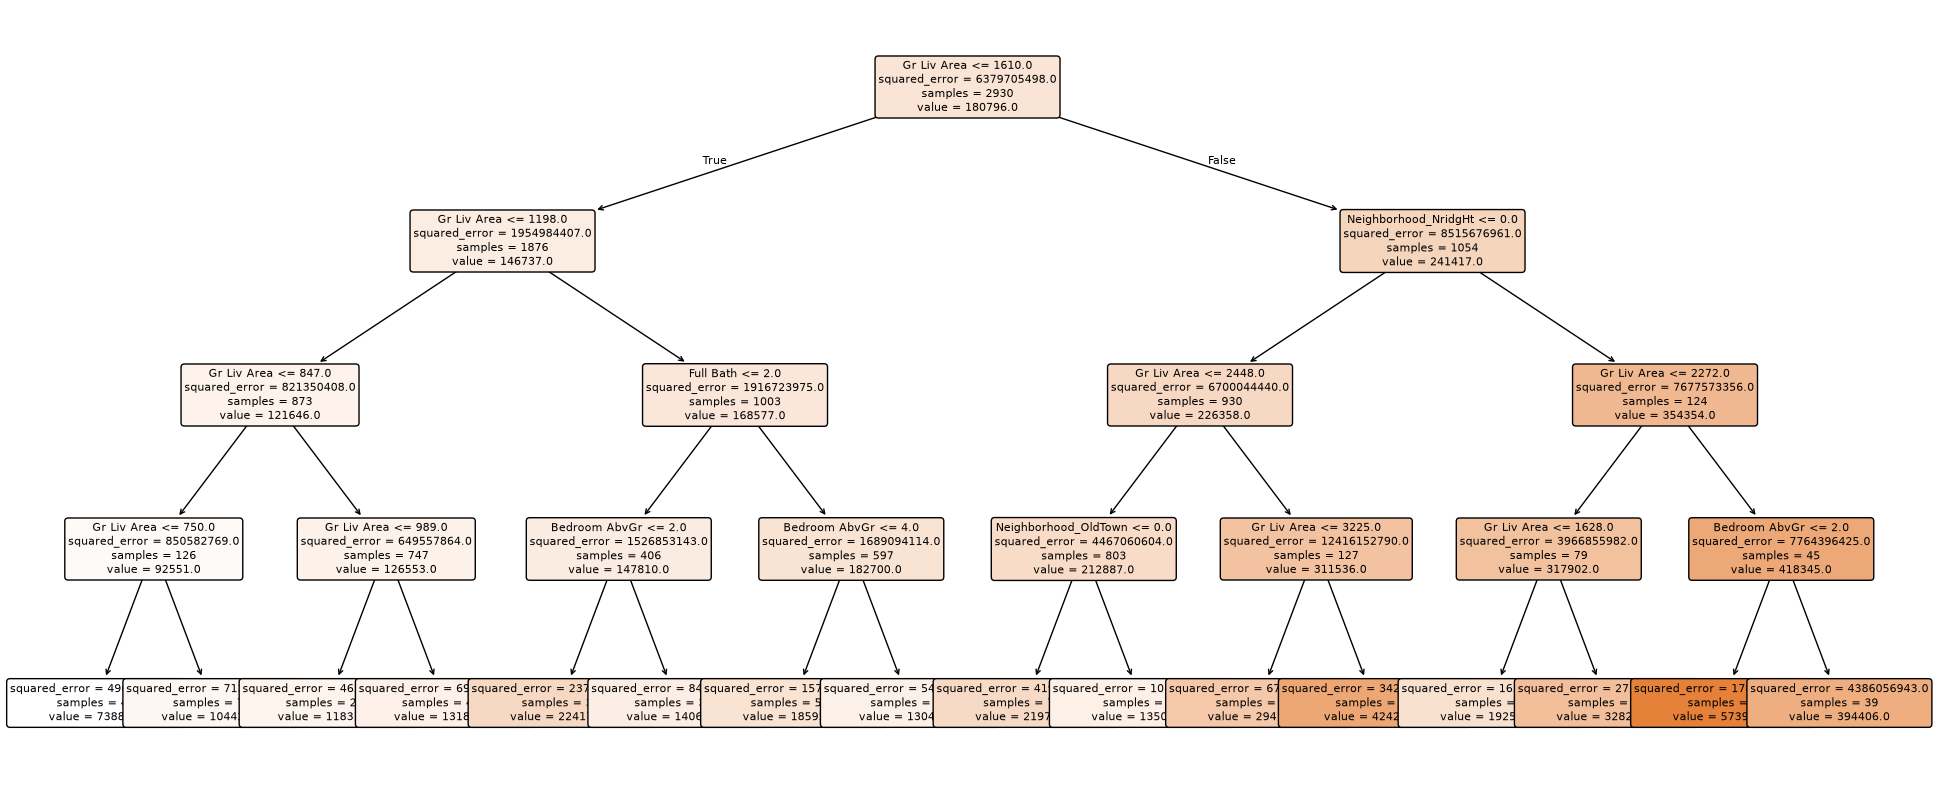

In [29]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

tree_preprocessing = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])],
    remainder="passthrough",          # the four numeric columns, unscaled
)
tree_pipe = Pipeline([
    ("preprocessing", tree_preprocessing),
    ("tree", DecisionTreeRegressor(max_depth=4, random_state=5544)),
])
tree_pipe.fit(X, y)

feature_names = [n.replace("dummify__", "").replace("remainder__", "")
                 for n in tree_pipe["preprocessing"].get_feature_names_out()]
plt.figure(figsize=(24, 10))
plot_tree(tree_pipe["tree"], feature_names=feature_names, filled=True, rounded=True, fontsize=8, precision=0);

RMSE on the fitted data: 47869
number of leaves: 16


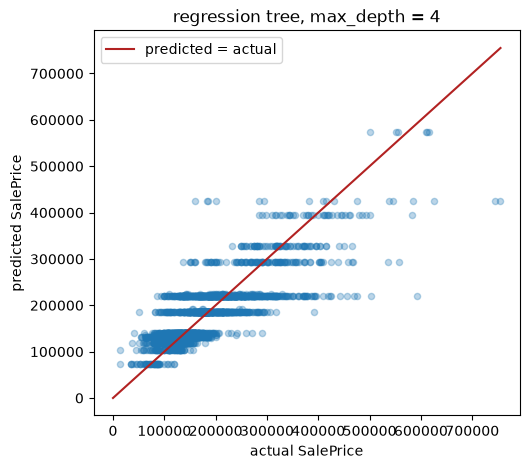

In [30]:
df_ames["predicted_tree4"] = tree_pipe.predict(X)
print("RMSE on the fitted data:", round(root_mean_squared_error(y, df_ames["predicted_tree4"])))
print("number of leaves:", tree_pipe["tree"].get_n_leaves())
predicted_vs_actual("predicted_tree4", "regression tree, max_depth = 4")

**What the code does.** `get_feature_names_out()` returns the transformer's column names
(`dummify__Neighborhood_Blueste`, …, `remainder__Gr Liv Area`); stripping the prefixes makes the plot readable.
`plot_tree` draws every node with its question, its `squared_error` (the mean squared error of prices around
the node mean), `samples` and `value` (the mean price, which is the prediction for that leaf).

**Expected output and interpretation.** The root asks **Gr Liv Area ≤ 1610.5 sq ft**: size is the single most
useful question. Below it, the small-house branch keeps splitting on size (1198.5, then 847 / 989 sq ft) with a
bathroom and bedroom question at the end; the large-house branch asks whether the house is in **NridgHt**
(Northridge Heights, the priciest neighborhood), then about size again (2447.5, 3225 sq ft) and, inside
NridgHt, about bedrooms. The 16 leaves predict from about **74,000** (under 750 sq ft) to **574,000** (NridgHt,
over 2,270 sq ft, two or fewer bedrooms). Reading a prediction: follow the questions from the top; e.g. a 1,400
sq ft house with 2 full baths and 3 bedrooms goes left (≤ 1610.5), right (> 1198.5), right (Full Bath > 1.5),
left (Bedroom ≤ 3.5): about 186,000.

The predicted-versus-actual plot has exactly **16 horizontal bands**, one per leaf; RMSE on the fitted data is
about **47,900**, worse than 10-NN's 34,700, because 16 flat values cannot track prices as finely as a local
average.

**Common mistakes.**
- Scaling the numeric features: harmless for the tree's accuracy (the splits are the same) but the thresholds
  come out in standard-deviation units (`Gr Liv Area ≤ 0.22`) and the tree becomes hard to read.
- Calling `plot_tree(tree_pipe)` on the pipeline instead of the tree step inside it.
- Forgetting the figure size: a depth-4 tree is 31 nodes wide and unreadable at the default size.

14. Repeat the previous part with different values of `max_depth`. What value of seems to be "best"? How are you deciding?

### Solution 14 — choosing max_depth

**Approach.** Exactly question 12 with `max_depth` in place of k: refit on the training rows for a range of
depths (including `None`, which grows the tree until every leaf is pure), record training and test RMSE, and
pick by test error.

In [31]:
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, None]:
    pipe = Pipeline([("preprocessing", tree_preprocessing),
                     ("tree", DecisionTreeRegressor(max_depth=depth, random_state=5544))])
    pipe.fit(X_tr, y_tr)
    rows.append({"max_depth": "None" if depth is None else depth,
                 "leaves": pipe["tree"].get_n_leaves(),
                 "train RMSE": root_mean_squared_error(y_tr, pipe.predict(X_tr)),
                 "test RMSE":  root_mean_squared_error(y_te, pipe.predict(X_te))})
depth_results = pd.DataFrame(rows).set_index("max_depth").round(0)
depth_results

,leaves,train RMSE,test RMSE
max_depth,,,
1,2,66549.0,63050.0
2,4,57916.0,60276.0
3,8,52754.0,53714.0
4,16,47097.0,49104.0
5,32,42808.0,46533.0
6,61,38309.0,43213.0
8,175,31556.0,40369.0
10,366,25664.0,39593.0
12,612,20465.0,39775.0


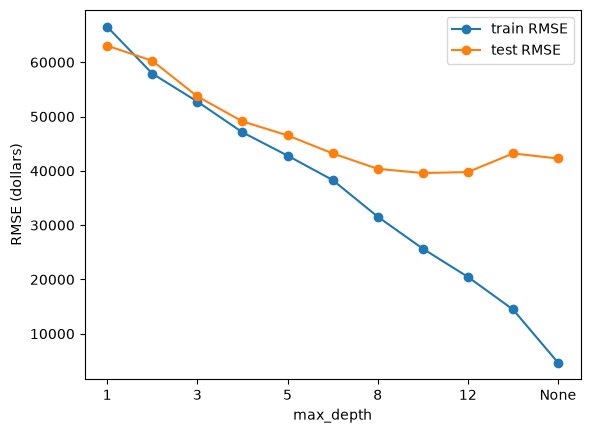

In [32]:
ax = depth_results[["train RMSE", "test RMSE"]].plot(marker="o")
ax.set_ylabel("RMSE (dollars)");

**What the code does.** The loop is the generic "tune one hyperparameter" pattern from Topic 8.2: create, fit
on train, score on train and test, collect.

**Expected output (random_state 5544).** Training RMSE falls at every step, from about 66,500 at depth 1 to
about 4,700 with no limit (thousands of leaves, essentially one per house). Test RMSE falls quickly — 63,000
(depth 1), 49,100 (depth 4), 43,200 (depth 6) — bottoms out around **depth 10 (≈ 39,600)**, then creeps back up
(≈ 43,100 at depth 15, ≈ 42,100 unlimited). **Decision:** the depth with the lowest test RMSE, about 10; depth 4
from question 13 was too shallow for prediction (though far easier to read), and an unlimited tree overfits.
Compared with KNN, the best tree (≈ 39,600) is a little worse than the best k (≈ 38,000) on this split.

**Common mistakes.**
- Choosing by training error, which always prefers the deepest tree.
- Reading `max_depth=None` as "no tree": it means no depth limit.
- Forgetting that a different random split moves these numbers by a few thousand dollars; the *shape* of the
  curves is the lesson, and cross-validation is the fix.